# PairA Brain correspondence diagnostics

This notebook performs three post-hoc analyses using the **existing** MOSCOT, SOCS and Pareto+feasible-set Stage2 transports.

1. **Expression-space error diagnosis**  
   MOSCOT Brain→Spinal and SOCS Brain→Spinal source spots vs the remaining source Brain, with target Brain / Spinal cord as NBVAE30 references.

2. **Rescue diagnosis**  
   Within each baseline's Brain→Spinal error cohort, compare spots that **Ours rescues to target Brain** with spots that **Ours does not rescue to Brain**.

3. **Spatial correspondence concentration**  
   Show connected high-density target regions reached by source Brain under MOSCOT / SOCS / Ours. Target Brain is not used as a background mask; target Spinal cord is highlighted.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import anndata as ad
import matplotlib.pyplot as plt

from scipy import sparse
from scipy.ndimage import gaussian_filter, label
from matplotlib.colors import LinearSegmentedColormap

try:
    import umap.umap_ as umap
except ImportError:
    import umap

# ------------------------- paths -------------------------
SRC_PATH = Path("/mnt/disk2/lirui/domain_concentration_repro/input/PairA_source_E9.5_E1S1.h5ad")
TGT_PATH = Path("/mnt/disk2/lirui/domain_concentration_repro/input/PairA_target_E10.5_E2S1.h5ad")

MOSCOT_ROOT = Path(
    "/mnt/disk2/lirui/mosta_growth_marginal_ablation/no_growth_score/"
    "E9.5_E1S1__E10.5_E2S1/results/E9.5_E1S1__E10.5_E2S1/X_nbvae_30"
)
SOCS_DIR = Path("/mnt/disk2/lirui/mosta_socs_official_unsupervised/PairA")
OURS_DIR = Path(
    "/mnt/disk2/lirui/mosta_e105_e115_baselines/pareto/"
    "PairA/src1_tgt0p6/stage2"
)

NBVAE_FALLBACK = Path(
    "/mnt/disk2/lirui/mosta_flatvi_fgw/data/E9.5__E10.5.nbvae30_latents.h5ad"
)

BRAIN, SPINAL = "Brain", "Spinal cord"

# ------------------------- colors -------------------------
C_BG = "#E2E2E2"
C_BRAIN = "#5B4CC4"
C_SPINAL = "#FF5AB3"
C_MOSCOT = "#D73027"
C_SOCS = "#F28E2B"
C_OURS = "#238B45"
C_FAIL = "#CB181D"

# ---------------- spatial concentration knobs -------------
BINS = 150
SIGMA_METHOD = 2.1
METHOD_BLOB_FLOOR = 0.01
MIN_COMPONENT_PIXELS = 10
TOP_COMPONENTS = 8

/mnt/disk1/lirui/anaconda3/envs/moscot/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load PairA and the three transports

In [2]:
src, tgt = ad.read_h5ad(SRC_PATH), ad.read_h5ad(TGT_PATH)
src_names, tgt_names = src.obs_names.astype(str).to_numpy(), tgt.obs_names.astype(str).to_numpy()
src_ann, tgt_ann = src.obs["annotation"].astype(str).to_numpy(), tgt.obs["annotation"].astype(str).to_numpy()
src_xy, tgt_xy = np.asarray(src.obsm["spatial"])[:, :2], np.asarray(tgt.obsm["spatial"])[:, :2]
ns, nt = src.n_obs, tgt.n_obs

def read_names(path):
    return None if not Path(path).exists() else np.atleast_1d(np.loadtxt(path, dtype=str)).astype(str)

def align(full_names, saved_names, adata):
    idx = pd.Index(full_names).get_indexer(saved_names)
    if np.any(idx < 0) and "original_obs_name" in adata.obs:
        idx = pd.Index(adata.obs["original_obs_name"].astype(str)).get_indexer(saved_names)
    if np.any(idx < 0):
        raise KeyError(f"Cannot align names, e.g. {saved_names[idx < 0][:5].tolist()}")
    return idx.astype(int)

def dense_top1(P_path, src_names_path, tgt_names_path):
    P = np.load(P_path, mmap_mode="r")
    ss, tt = read_names(src_names_path), read_names(tgt_names_path)
    si = np.arange(ns) if ss is None else align(src_names, ss, src)
    ti = np.arange(nt) if tt is None else align(tgt_names, tt, tgt)
    if P.shape != (len(si), len(ti)):
        raise ValueError(f"{P_path}: {P.shape} != {(len(si), len(ti))}")

    out = np.full(ns, -1, dtype=np.int32)
    for lo in range(0, P.shape[0], 512):
        hi = min(lo + 512, P.shape[0])
        block = np.asarray(P[lo:hi], dtype=np.float32)
        active = np.isfinite(block).all(1) & (block.sum(1) > 0)
        rows = si[lo:hi][active]
        out[rows] = ti[np.argmax(block[active], axis=1)]
    return out

def sparse_top1(path):
    z = np.load(path)
    offsets, idx, mass = z["row_offsets"], z["target_indices"], z["mass"]
    out = np.full(ns, -1, dtype=np.int32)
    for i in range(ns):
        lo, hi = offsets[i], offsets[i + 1]
        if hi > lo:
            row = mass[lo:hi]
            if np.isfinite(row).all() and row.sum() > 0:
                out[i] = idx[lo + np.argmax(row)]
    return out

# weighted-best MOSCOT
rows = []
for p in MOSCOT_ROOT.glob("task_*/metrics.json"):
    m = json.loads(p.read_text())
    w = m.get("accuracy", m.get("weighted_accuracy"))
    if m.get("status") == "success" and w is not None:
        rows.append((float(w), int(m["task_id"]), p.parent))
if not rows:
    raise RuntimeError("No successful MOSCOT task found.")
_, _, MOSCOT_DIR = max(rows, key=lambda x: (x[0], -x[1]))

top1_moscot = dense_top1(
    MOSCOT_DIR / "transport.npy",
    MOSCOT_DIR / "source_obs_names.txt",
    MOSCOT_DIR / "target_obs_names.txt",
)
top1_socs = dense_top1(
    SOCS_DIR / "best_transport.npy",
    SOCS_DIR / "source_obs_names.txt",
    SOCS_DIR / "target_obs_names.txt",
)

ours_hits = list(OURS_DIR.glob("*_transport_sparse.npz"))
if len(ours_hits) != 1:
    raise RuntimeError(f"Expected one Ours sparse transport, found {ours_hits}")
top1_ours = sparse_top1(ours_hits[0])

brain_idx = np.flatnonzero(src_ann == BRAIN)
target_brain_idx = np.flatnonzero(tgt_ann == BRAIN)
target_spinal_idx = np.flatnonzero(tgt_ann == SPINAL)

def bad_to_spinal(top1):
    i = brain_idx[top1[brain_idx] >= 0]
    return i[tgt_ann[top1[i]] == SPINAL]

bad_moscot, bad_socs = bad_to_spinal(top1_moscot), bad_to_spinal(top1_socs)
other_moscot = np.setdiff1d(brain_idx, bad_moscot)
other_socs = np.setdiff1d(brain_idx, bad_socs)

def split_rescue(bad):
    active = bad[top1_ours[bad] >= 0]
    lab = tgt_ann[top1_ours[active]]
    return active[lab == BRAIN], active[lab != BRAIN]

rescue_m, fail_m = split_rescue(bad_moscot)
rescue_s, fail_s = split_rescue(bad_socs)

print(f"source Brain: {len(brain_idx):,}")
print(f"MOSCOT Brain→Spinal: {len(bad_moscot):,} | rescued by Ours: {len(rescue_m):,}")
print(f"SOCS   Brain→Spinal: {len(bad_socs):,} | rescued by Ours: {len(rescue_s):,}")

source Brain: 1,518
MOSCOT Brain→Spinal: 40 | rescued by Ours: 23
SOCS   Brain→Spinal: 212 | rescued by Ours: 143


## 2. Load NBVAE30 once and compute one joint UMAP

In [3]:
def nbvae_key(a):
    preferred = ["X_nbvae_30", "X_nbvae30", "nbvae_30", "nbvae30"]
    for k in preferred:
        if k in a.obsm and np.asarray(a.obsm[k]).shape[1] == 30:
            return k
    hits = [k for k in a.obsm if "nbvae" in k.lower() and np.asarray(a.obsm[k]).shape[1] == 30]
    return hits[0] if len(hits) == 1 else None

ks, kt = nbvae_key(src), nbvae_key(tgt)

if ks and kt:
    Zs, Zt = np.asarray(src.obsm[ks]), np.asarray(tgt.obsm[kt])
else:
    lat = ad.read_h5ad(NBVAE_FALLBACK)
    k = nbvae_key(lat)
    Z = np.asarray(lat.obsm[k]) if k else (lat.X.toarray() if sparse.issparse(lat.X) else np.asarray(lat.X))
    names = lat.obs_names.astype(str).to_numpy()
    if "original_obs_name" in lat.obs:
        original = lat.obs["original_obs_name"].astype(str).to_numpy()
    else:
        original = names

    def lookup(q):
        ix = pd.Index(names).get_indexer(q)
        if np.any(ix < 0):
            ix = pd.Index(original).get_indexer(q)
        if np.any(ix < 0):
            raise KeyError("NBVAE30 row alignment failed.")
        return ix

    Zs, Zt = Z[lookup(src_names)], Z[lookup(tgt_names)]

if Zs.shape[1] != 30 or Zt.shape[1] != 30:
    raise ValueError(f"Expected NBVAE30, got {Zs.shape} and {Zt.shape}")

U = umap.UMAP(n_neighbors=30, min_dist=0.30, random_state=0).fit_transform(np.vstack([Zs, Zt]))
Us, Ut = U[:ns], U[ns:]
print("Joint NBVAE30 UMAP:", Us.shape, Ut.shape)

/mnt/disk1/lirui/anaconda3/envs/moscot/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Joint NBVAE30 UMAP: (5870, 2) (8494, 2)


## 3. Expression-space diagnosis: baseline Brain→Spinal errors

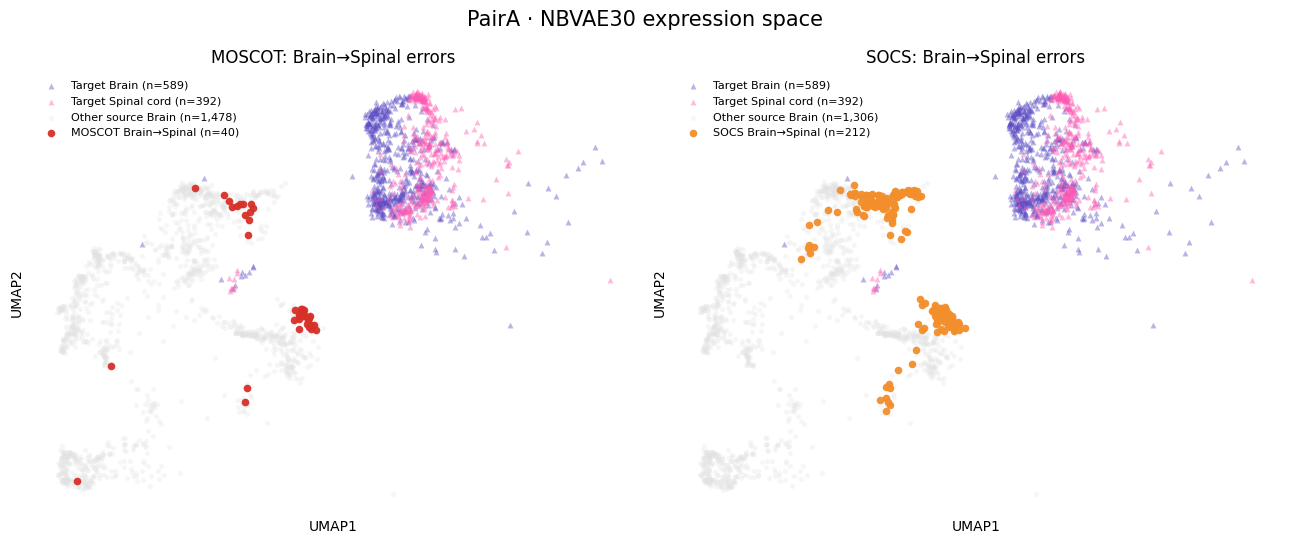

In [4]:
def umap_refs(ax, alpha=0.42):
    ax.scatter(Ut[target_brain_idx,0], Ut[target_brain_idx,1], s=18, c=C_BRAIN, alpha=alpha,
               marker="^", lw=0, label=f"Target Brain (n={len(target_brain_idx):,})")
    ax.scatter(Ut[target_spinal_idx,0], Ut[target_spinal_idx,1], s=18, c=C_SPINAL, alpha=alpha,
               marker="^", lw=0, label=f"Target Spinal cord (n={len(target_spinal_idx):,})")

def clean_umap(ax):
    ax.set(xticks=[], yticks=[], xlabel="UMAP1", ylabel="UMAP2")
    for s in ax.spines.values(): s.set_visible(False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for ax, bad, other, name, color in [
    (axes[0], bad_moscot, other_moscot, "MOSCOT", C_MOSCOT),
    (axes[1], bad_socs, other_socs, "SOCS", C_SOCS),
]:
    umap_refs(ax)
    ax.scatter(Us[other,0], Us[other,1], s=14, c=C_BG, alpha=.28, lw=0,
               label=f"Other source Brain (n={len(other):,})")
    ax.scatter(Us[bad,0], Us[bad,1], s=30, c=color, alpha=.95, lw=0,
               label=f"{name} Brain→Spinal (n={len(bad):,})")
    ax.set_title(f"{name}: Brain→Spinal errors")
    ax.legend(frameon=False, fontsize=8)
    clean_umap(ax)

fig.suptitle("PairA · NBVAE30 expression space", fontsize=15)
plt.tight_layout()
plt.show()

## 4. Rescue diagnosis: Ours rescued vs not rescued

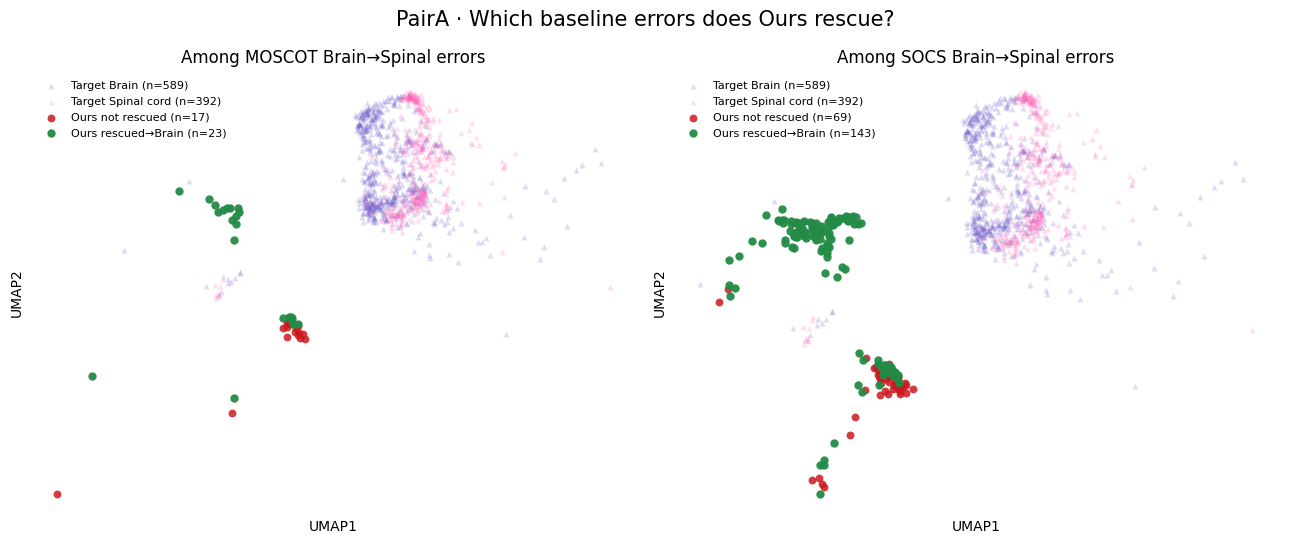

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for ax, rescued, failed, name in [
    (axes[0], rescue_m, fail_m, "MOSCOT"),
    (axes[1], rescue_s, fail_s, "SOCS"),
]:
    umap_refs(ax, alpha=.20)
    ax.scatter(Us[failed,0], Us[failed,1], s=32, c=C_FAIL, alpha=.85, lw=0,
               label=f"Ours not rescued (n={len(failed):,})")
    ax.scatter(Us[rescued,0], Us[rescued,1], s=36, c=C_OURS, alpha=.95, lw=0,
               label=f"Ours rescued→Brain (n={len(rescued):,})")
    ax.set_title(f"Among {name} Brain→Spinal errors")
    ax.legend(frameon=False, fontsize=8)
    clean_umap(ax)

fig.suptitle("PairA · Which baseline errors does Ours rescue?", fontsize=15)
plt.tight_layout()
plt.show()

## 5. Spatial correspondence: connected concentrated target regions

Only the **connected high-density target correspondence regions** are shown.  
Target Brain is intentionally not colored. Target Spinal cord is highlighted so Brain→Spinal leakage remains visible.


/mnt/disk2/lirui/tmp/ipykernel_1568190/1874547605.py:32: UserWarning: The following kwargs were not used by contour: 'lw'
  ax.contour(X, Y, Hemb, [thr_emb], colors=["#B8B8B8"], lw=.8, alpha=.55)


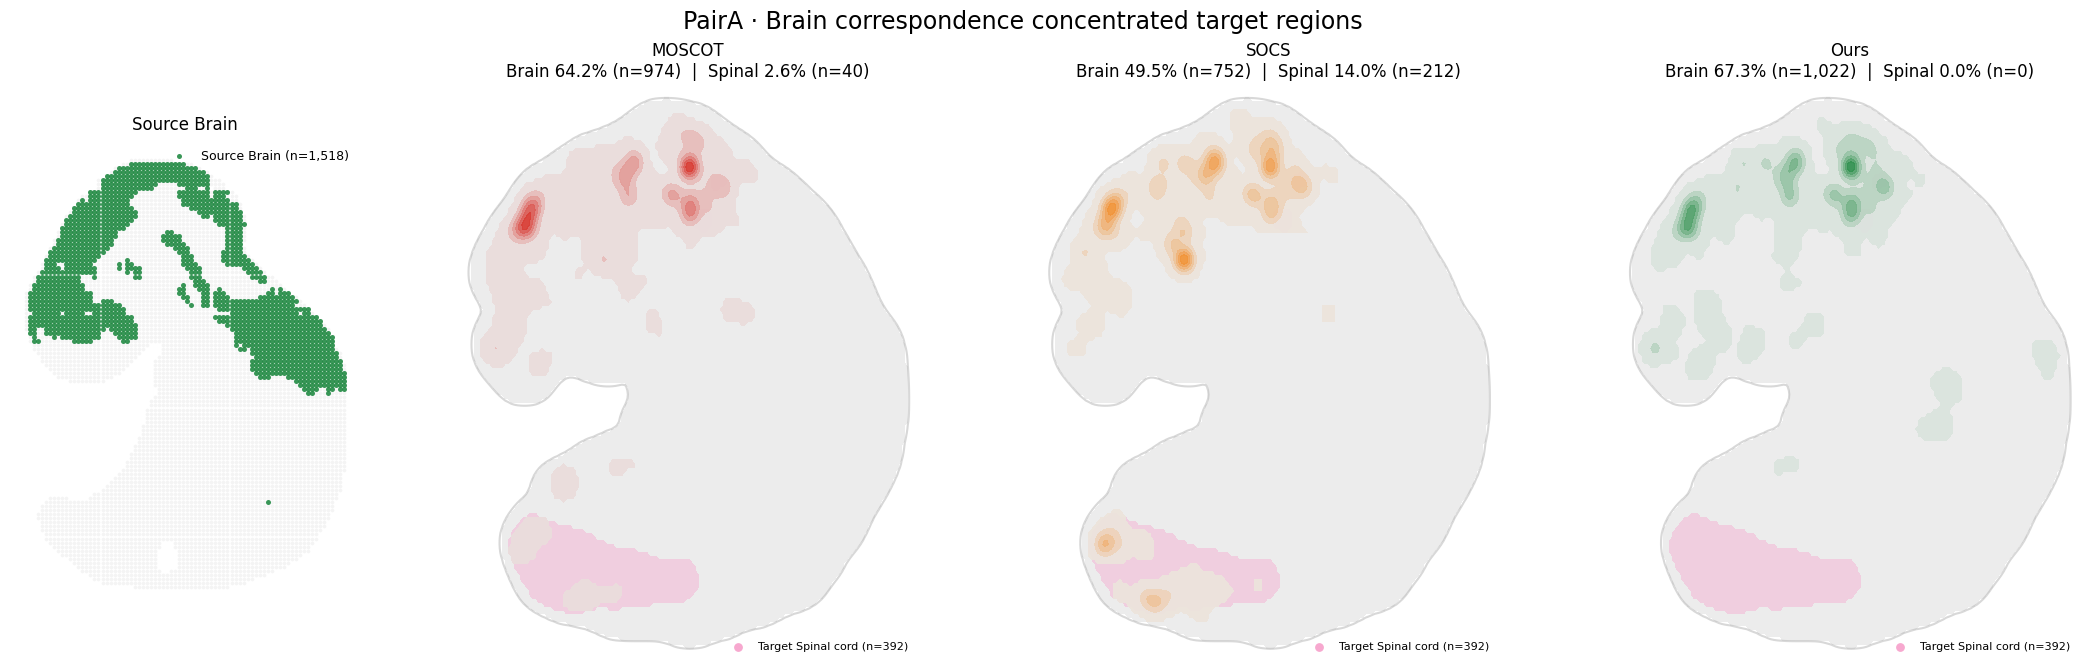

In [6]:
# target destinations of all source Brain spots
def destinations(top1):
    active = brain_idx[top1[brain_idx] >= 0]
    d = top1[active]
    return d, tgt_ann[d]

moscot_dest, moscot_labels = destinations(top1_moscot)
socs_dest, socs_labels = destinations(top1_socs)
ours_dest, ours_labels = destinations(top1_ours)

# common grid
pad = .07
xmin, xmax = tgt_xy[:,0].min(), tgt_xy[:,0].max()
ymin, ymax = tgt_xy[:,1].min(), tgt_xy[:,1].max()
xr, yr = xmax-xmin, ymax-ymin
extent = [xmin-pad*xr, xmax+pad*xr, ymin-pad*yr, ymax+pad*yr]

def smooth_hist(xy, sigma):
    H, xe, ye = np.histogram2d(xy[:,0], xy[:,1], bins=BINS,
                               range=[[extent[0],extent[1]],[extent[2],extent[3]]])
    H = gaussian_filter(H, sigma).T
    X, Y = np.meshgrid((xe[:-1]+xe[1:])/2, (ye[:-1]+ye[1:])/2)
    return X, Y, H

X, Y, Hemb = smooth_hist(tgt_xy, 2.7)
_, _, Hsp = smooth_hist(tgt_xy[target_spinal_idx], 2.0)
thr_emb, thr_sp = .018*Hemb.max(), .035*Hsp.max()

def background(ax):
    ax.contourf(X, Y, np.ma.masked_less(Hemb, thr_emb), [thr_emb, Hemb.max()],
                colors=["#ECECEC"], zorder=0)
    ax.contour(X, Y, Hemb, [thr_emb], colors=["#B8B8B8"], lw=.8, alpha=.55)
    ax.contourf(X, Y, np.ma.masked_less(Hsp, thr_sp), [thr_sp, Hsp.max()],
                colors=["#F7A8CF"], alpha=.43, zorder=2)
    ax.scatter([], [], s=28, c="#F7A8CF", label=f"Target Spinal cord (n={len(target_spinal_idx):,})")

def blob_mask(dest):
    Xd, Yd, H = smooth_hist(tgt_xy[dest], SIGMA_METHOD)
    binary = H >= METHOD_BLOB_FLOOR * H.max()
    lab, n = label(binary, structure=np.ones((3,3), int))
    comps = []
    for k in range(1, n+1):
        m = lab == k
        if m.sum() >= MIN_COMPONENT_PIXELS:
            comps.append((H[m].sum(), k))
    keep = np.zeros_like(binary)
    for _, k in sorted(comps, reverse=True)[:TOP_COMPONENTS]:
        keep |= lab == k
    return Xd, Yd, H, keep

def draw_blobs(ax, dest, color):
    Xd, Yd, H, keep = blob_mask(dest)
    if not keep.any(): return
    h = np.ma.masked_where(~keep, H)
    vals = H[keep]
    cmap = LinearSegmentedColormap.from_list("blob", ["#ECECEC", color])
    ax.contourf(Xd, Yd, h, np.linspace(vals.min(), vals.max()+1e-8, 7),
                cmap=cmap, alpha=.95, zorder=5)

def clean_spatial(ax):
    ax.set_xlim(extent[:2]); ax.set_ylim(extent[3], extent[2])
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values(): s.set_visible(False)

def method_panel(ax, dest, labels, name, color):
    background(ax); draw_blobs(ax, dest, color)
    b, s = (labels == BRAIN), (labels == SPINAL)
    ax.set_title(f"{name}\nBrain {b.mean():.1%} (n={b.sum():,})  |  Spinal {s.mean():.1%} (n={s.sum():,})")
    ax.legend(frameon=False, fontsize=8, loc="lower right")
    clean_spatial(ax)

fig = plt.figure(figsize=(27, 7.5))
gs = fig.add_gridspec(1, 4, width_ratios=[.9, 1.3, 1.3, 1.3], wspace=.16)
axes = [fig.add_subplot(gs[0,i]) for i in range(4)]

# source
ax = axes[0]
ax.scatter(src_xy[:,0], src_xy[:,1], s=7, c="#ECECEC", alpha=.55, lw=0)
ax.scatter(src_xy[brain_idx,0], src_xy[brain_idx,1], s=13, c=C_OURS, alpha=.9, lw=0,
           label=f"Source Brain (n={len(brain_idx):,})")
sx0,sx1,sy0,sy1 = src_xy[:,0].min(),src_xy[:,0].max(),src_xy[:,1].min(),src_xy[:,1].max()
ax.set_xlim(sx0-.05*(sx1-sx0),sx1+.05*(sx1-sx0))
ax.set_ylim(sy1+.05*(sy1-sy0),sy0-.05*(sy1-sy0))
ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
for s in ax.spines.values(): s.set_visible(False)
ax.set_title("Source Brain"); ax.legend(frameon=False, fontsize=9)

method_panel(axes[1], moscot_dest, moscot_labels, "MOSCOT", C_MOSCOT)
method_panel(axes[2], socs_dest, socs_labels, "SOCS", C_SOCS)
method_panel(axes[3], ours_dest, ours_labels, "Ours", C_OURS)

fig.suptitle("PairA · Brain correspondence concentrated target regions", fontsize=17)
plt.show()